# Câu 5: Thống kê số lần liên hệ (campaign, previous) và khảo sát sự liên quan với khả năng đăng ký

Phần 1 – Bài 2 (trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing giống phần hướng dẫn.

Dữ liệu dùng: `bank-full.csv` (45.211 khách hàng, 16 thuộc tính + thuộc tính quyết định `y` – có đăng ký gửi tiền có kỳ hạn hay không).

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_csv(DATA + 'bank-full.csv', sep=';')
df['y_num'] = (df['y'] == 'yes').astype(int)   # dùng để tính tỷ lệ đăng ký

---
## Thực hiện yêu cầu

In [4]:
print(SV)
df['contacted_before'] = (df['previous'] > 0).astype(int)
df['contacted_before'].value_counts()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


contacted_before
0    36954
1     8257
Name: count, dtype: int64

In [5]:
df.groupby('contacted_before')['y_num'].agg(['count', 'mean']).round(3)

,count,mean
contacted_before,,
0,36954,0.092
1,8257,0.231


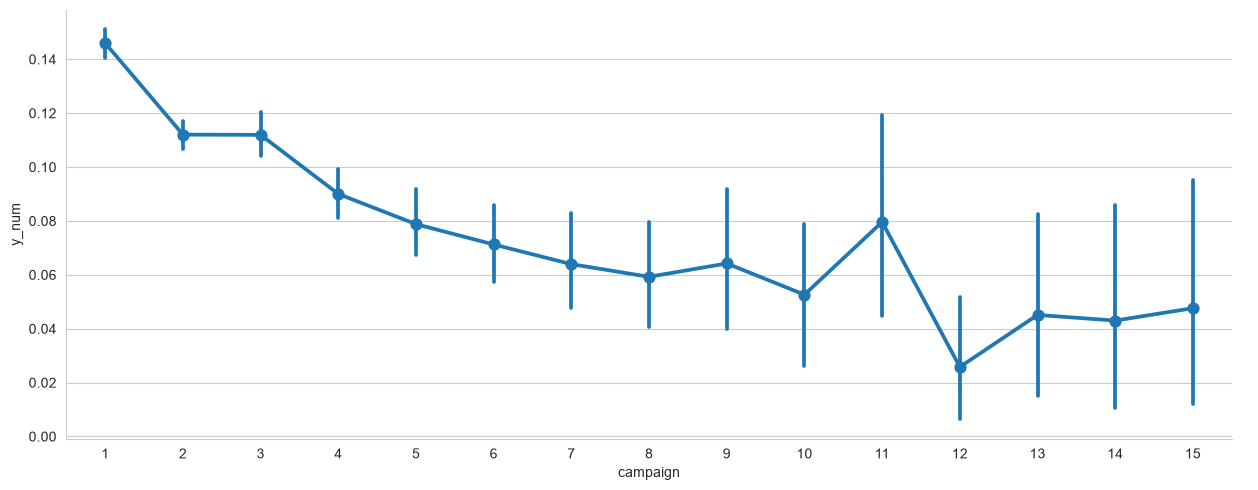

In [6]:
d = df[df['campaign'] <= 15]
sns.catplot(x='campaign', y='y_num', data=d, aspect=2.5, kind='point')
plt.show()

Thời lượng cuộc gọi cuối (duration) theo kết quả:

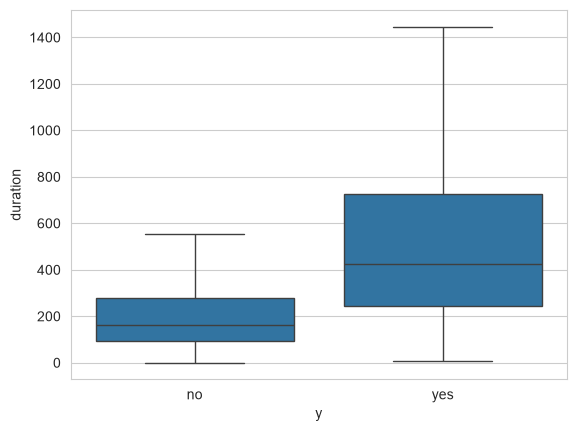

y
no     164.0
yes    426.0
Name: duration, dtype: float64

In [7]:
sns.boxplot(x='y', y='duration', data=df, showfliers=False)
plt.show()
df.groupby('y')['duration'].median()

**Nhận xét:**

- 36.954 khách chưa từng được liên hệ ở chiến dịch trước, 8.257 khách đã từng được liên hệ.
- Khách đã từng được liên hệ có tỷ lệ đăng ký ≈23,1%, cao gấp 2,5 lần khách mới (≈9,2%).
- Ngược lại, gọi nhiều lần trong cùng chiến dịch (`campaign`) làm tỷ lệ đăng ký giảm dần: ≈14,6% ở lần gọi đầu tiên, còn ≈5–8% sau 5 lần và dưới 5% từ lần thứ 12.
- Cuộc gọi của khách đăng ký dài hơn nhiều (trung vị 426 giây so với 164 giây). Tuy nhiên `duration` chỉ biết được *sau* cuộc gọi, nên khi xây dựng mô hình dự đoán thật cần cân nhắc bỏ thuộc tính này.